# Aircraft Engine Remaining Useful Life (RUL) Prediction
## End-to-End Predictive Analytics / KDD Project

**Objective:** Predict the Remaining Useful Life (RUL), measured in operating cycles, of aircraft engines using historical sensor data from the NASA C-MAPSS FD001, FD002, FD003 and FD004 datasets.

This notebook follows the main Predictive Analytics / KDD stages:

1. Problem identification
2. Data loading and understanding
3. Data preparation and preprocessing
4. RUL target creation
5. Train-validation split by engine
6. Predictive modelling
7. Model evaluation and comparison
8. Test-set prediction and interpretation
9. Export results

## 1. Import libraries
We use pandas and NumPy for data handling, Matplotlib for visualisation, and scikit-learn for preprocessing, regression models and evaluation.

In [1]:
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Locate the dataset files

The code searches common locations for the four sets of files. If your files are inside a folder named `dataset` or `Dataset`, the notebook should find them automatically. If they are stored somewhere else, update `DATA_DIR` below.

Required files for each subset: `train_FD00X.txt`, `test_FD00X.txt` and `RUL_FD00X.txt`.

In [2]:
# Change this path if your dataset folder is stored somewhere else.
possible_dirs = [
    Path("dataset"),
    Path("Dataset"),
    Path("data"),
    Path("."),
    Path("/mnt/data"),
    Path("/mnt/data/dataset"),
    Path("/mnt/data/Dataset"),
]

DATA_DIR = None
for folder in possible_dirs:
    if all((folder / f"train_FD00{i}.txt").exists() for i in range(1, 5)):
        DATA_DIR = folder
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find train_FD001.txt through train_FD004.txt. "
        "Set DATA_DIR to the folder containing the C-MAPSS text files."
    )

print("Dataset folder:", DATA_DIR.resolve())
for subset in range(1, 5):
    for prefix in ["train", "test", "RUL"]:
        file_path = DATA_DIR / f"{prefix}_FD00{subset}.txt"
        print(f"{file_path.name}: {'found' if file_path.exists() else 'MISSING'}")

Dataset folder: C:\Users\Aman Shrikhande\Desktop\PA-Project\data
train_FD001.txt: found
test_FD001.txt: found
RUL_FD001.txt: found
train_FD002.txt: found
test_FD002.txt: found
RUL_FD002.txt: found
train_FD003.txt: found
test_FD003.txt: found
RUL_FD003.txt: found
train_FD004.txt: found
test_FD004.txt: found
RUL_FD004.txt: found


## 3. Define dataset columns and loading functions

Each row contains an engine identifier, a cycle number, three operating settings and 21 sensor readings. The raw files are whitespace-separated and do not include a header row.

In [3]:
COLUMN_NAMES = (
    ["unit_number", "time_in_cycles"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

ID_COL = "unit_number"
CYCLE_COL = "time_in_cycles"
TARGET_COL = "RUL"

def read_cmapss_file(file_path):
    # sep=r"\\s+" correctly handles one or more spaces between values.
    df = pd.read_csv(file_path, sep=r"\s+", header=None, engine="python")
    # Some copies of these files contain trailing empty columns; remove fully empty columns.
    df = df.dropna(axis=1, how="all")
    if df.shape[1] != len(COLUMN_NAMES):
        raise ValueError(
            f"{file_path.name} has {df.shape[1]} columns; expected {len(COLUMN_NAMES)}. "
            "Check that the correct C-MAPSS file was loaded."
        )
    df.columns = COLUMN_NAMES
    return df

def load_rul_reference(file_path):
    values = pd.read_csv(file_path, sep=r"\s+", header=None, engine="python").iloc[:, 0]
    return values.astype(float).to_numpy()

print("Column count:", len(COLUMN_NAMES))
print("First columns:", COLUMN_NAMES[:8])

Column count: 26
First columns: ['unit_number', 'time_in_cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3']


## 4. Load and understand all four datasets

We inspect the number of rows, engines and columns. We also check missing values and review a sample of the data. These steps correspond to the data-understanding stage of KDD.

In [4]:
datasets = {}

for subset in range(1, 5):
    name = f"FD00{subset}"
    train_path = DATA_DIR / f"train_{name}.txt"
    test_path = DATA_DIR / f"test_{name}.txt"
    rul_path = DATA_DIR / f"RUL_{name}.txt"

    missing = [p.name for p in [train_path, test_path, rul_path] if not p.exists()]
    if missing:
        raise FileNotFoundError(f"Missing files for {name}: {missing}")

    train_df = read_cmapss_file(train_path)
    test_df = read_cmapss_file(test_path)
    rul_ref = load_rul_reference(rul_path)

    datasets[name] = {"train": train_df, "test": test_df, "rul_reference": rul_ref}

    print(f"\\n{name}")
    print("Training rows:", len(train_df), "| training engines:", train_df[ID_COL].nunique())
    print("Test rows:", len(test_df), "| test engines:", test_df[ID_COL].nunique())
    print("Reference RUL values:", len(rul_ref))
    print("Training missing values:", int(train_df.isna().sum().sum()))
    print("Test missing values:", int(test_df.isna().sum().sum()))

display(datasets["FD001"]["train"].head())

\nFD001
Training rows: 20631 | training engines: 100
Test rows: 13096 | test engines: 100
Reference RUL values: 100
Training missing values: 0
Test missing values: 0
\nFD002
Training rows: 53759 | training engines: 260
Test rows: 33991 | test engines: 259
Reference RUL values: 259
Training missing values: 0
Test missing values: 0
\nFD003
Training rows: 24720 | training engines: 100
Test rows: 16596 | test engines: 100
Reference RUL values: 100
Training missing values: 0
Test missing values: 0
\nFD004
Training rows: 61249 | training engines: 249
Test rows: 41214 | test engines: 248
Reference RUL values: 248
Training missing values: 0
Test missing values: 0


,unit_number,time_in_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 5. Exploratory Data Analysis (EDA)

We examine engine lifetimes and sensor behaviour. EDA helps us understand the dataset before modelling; it does not itself make predictions.

In [5]:
# Compare the number of training engines and their final observed cycles.
summary_rows = []
for name, data in datasets.items():
    train_df = data["train"]
    engine_last_cycles = train_df.groupby(ID_COL)[CYCLE_COL].max()
    summary_rows.append({
        "Dataset": name,
        "Training engines": train_df[ID_COL].nunique(),
        "Training rows": len(train_df),
        "Average last cycle": round(engine_last_cycles.mean(), 2),
        "Minimum last cycle": int(engine_last_cycles.min()),
        "Maximum last cycle": int(engine_last_cycles.max()),
        "Test engines": data["test"][ID_COL].nunique(),
    })

dataset_summary = pd.DataFrame(summary_rows)
display(dataset_summary)

,Dataset,Training engines,Training rows,Average last cycle,Minimum last cycle,Maximum last cycle,Test engines
0,FD001,100,20631,206.31,128,362,100
1,FD002,260,53759,206.77,128,378,259
2,FD003,100,24720,247.20,145,525,100
3,FD004,249,61249,245.98,128,543,248


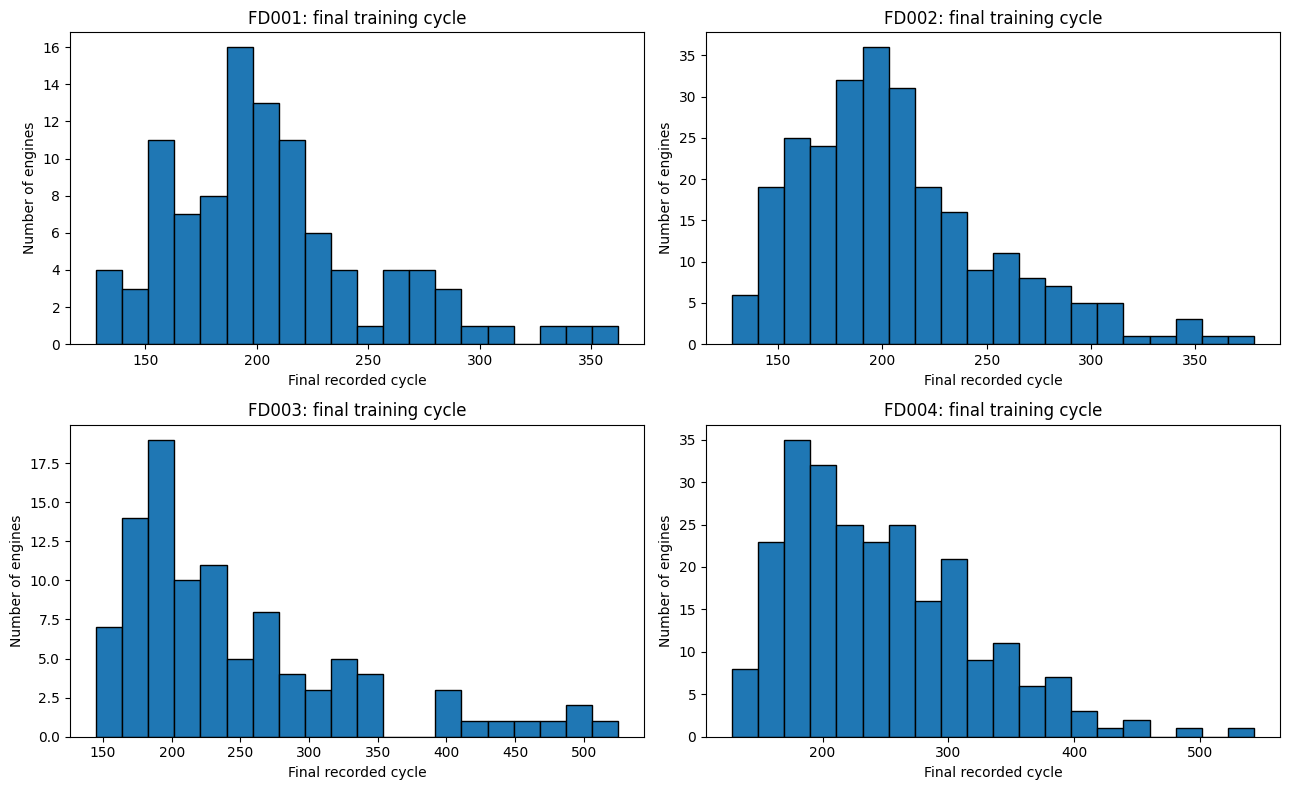

In [6]:
# Visualise training-engine lifetimes for each dataset.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (name, data) in zip(axes.flat, datasets.items()):
    last_cycles = data["train"].groupby(ID_COL)[CYCLE_COL].max()
    ax.hist(last_cycles, bins=20, edgecolor="black")
    ax.set_title(f"{name}: final training cycle")
    ax.set_xlabel("Final recorded cycle")
    ax.set_ylabel("Number of engines")
plt.tight_layout()
plt.show()

In [7]:
# Display sensor statistics for FD001 as an example.
display(datasets["FD001"]["train"].describe().T.head(12))

,count,mean,std,min,25%,50%,75%,max
unit_number,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.00,77.0000,100.0000
time_in_cycles,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.00,156.0000,362.0000
op_setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.00,0.0015,0.0087
op_setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.00,0.0003,0.0006
op_setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.00,100.0000,100.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.67,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.64,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.10,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.04,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.62,14.6200,14.6200


## 6. Create RUL labels for training data

The training data contains complete engine trajectories, so each engine's final recorded cycle is known. We create a target label for every training row:

**RUL = engine's maximum recorded training cycle − current cycle**

For example, if an engine's maximum training cycle is 200, the row at cycle 150 receives an RUL label of 50. Test engines have partial histories, so we do not calculate their RUL from their own maximum observed cycle.

In [8]:
def add_training_rul(train_df):
    df = train_df.copy()
    max_cycle = df.groupby(ID_COL)[CYCLE_COL].transform("max")
    df[TARGET_COL] = max_cycle - df[CYCLE_COL]
    return df

for name in datasets:
    datasets[name]["train_labeled"] = add_training_rul(datasets[name]["train"])

display(datasets["FD001"]["train_labeled"][
    [ID_COL, CYCLE_COL, TARGET_COL]
].head(10))

,unit_number,time_in_cycles,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


## 7. Prepare features and split by engine

- `unit_number` is used only to group engine histories and is not a model input.
- `RUL` is the target, so it is not included among the features.
- Constant sensor columns are removed using the training data only.
- The validation split is made by engine ID, not by random rows. This prevents the same engine from appearing in both training and validation.
- We use approximately 80% of the engines for training and 20% for validation.

In [9]:
def get_feature_columns(train_df):
    candidate_features = [
        c for c in train_df.columns
        if c not in [ID_COL, TARGET_COL]
    ]
    # Remove features with no variation in this training subset.
    non_constant = [c for c in candidate_features if train_df[c].nunique(dropna=False) > 1]
    return non_constant

def split_by_engine(df, test_size=0.2, random_state=RANDOM_STATE):
    splitter = GroupShuffleSplit(
        n_splits=1, test_size=test_size, random_state=random_state
    )
    X_placeholder = np.zeros((len(df), 1))
    groups = df[ID_COL].to_numpy()
    train_idx, val_idx = next(splitter.split(X_placeholder, groups=groups))
    return df.iloc[train_idx].copy(), df.iloc[val_idx].copy()

# Show split sizes for all four datasets.
for name, data in datasets.items():
    labeled = data["train_labeled"]
    tr_df, val_df = split_by_engine(labeled)
    print(
        name,
        "| train engines:", tr_df[ID_COL].nunique(),
        "| validation engines:", val_df[ID_COL].nunique(),
        "| feature count:", len(get_feature_columns(tr_df))
    )

FD001 | train engines: 80 | validation engines: 20 | feature count: 18
FD002 | train engines: 208 | validation engines: 52 | feature count: 25
FD003 | train engines: 80 | validation engines: 20 | feature count: 19
FD004 | train engines: 199 | validation engines: 50 | feature count: 25


## 8. Define simple regression models

We use three standard regression algorithms appropriate for an introductory predictive analytics project:

1. **Linear Regression:** Learns a weighted equation between features and RUL.
2. **Decision Tree Regressor:** Learns feature-threshold rules and predicts from a leaf.
3. **Random Forest Regressor:** Averages predictions from multiple decision trees.

No CNN, LSTM, neural network or deep-learning code is used in this notebook. Imputation and scaling are placed inside pipelines so preprocessing is fitted only on training data.

In [10]:
def build_models(random_state=RANDOM_STATE):
    return {
        "Linear Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ]),
        "Decision Tree": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeRegressor(
                max_depth=12, min_samples_leaf=5, random_state=random_state
            ))
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=60,
                max_depth=20,
                min_samples_leaf=2,
                random_state=random_state,
                n_jobs=-1
            ))
        ])
    }

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

print("Models ready:", list(build_models().keys()))

Models ready: ['Linear Regression', 'Decision Tree', 'Random Forest']


## 9. Train and validate models on each dataset

Each FD subset is handled independently. We train the three models on the training engines, predict RUL for the held-out validation engines, and calculate MAE, RMSE and R².

- **MAE:** average absolute prediction error, in cycles; lower is better.
- **RMSE:** gives larger errors more influence, in cycles; lower is better.
- **R²:** indicates how well predictions explain variation in the target; closer to 1 is generally better, but it can be negative.

The validation set is used to compare models. The separate official test files are evaluated later.

In [11]:
validation_results = []
validation_predictions = {}
validation_feature_columns = {}

for name, data in datasets.items():
    labeled = data["train_labeled"]
    train_part, val_part = split_by_engine(labeled)
    feature_cols = get_feature_columns(train_part)

    X_train = train_part[feature_cols]
    y_train = train_part[TARGET_COL]
    X_val = val_part[feature_cols]
    y_val = val_part[TARGET_COL]

    validation_feature_columns[name] = feature_cols
    validation_predictions[name] = {}

    for model_name, model in build_models().items():
        model.fit(X_train, y_train)
        pred = model.predict(X_val)
        metrics = regression_metrics(y_val, pred)

        validation_results.append({
            "Dataset": name,
            "Model": model_name,
            **metrics,
            "Training engines": train_part[ID_COL].nunique(),
            "Validation engines": val_part[ID_COL].nunique(),
            "Features": len(feature_cols)
        })
        validation_predictions[name][model_name] = {
            "model": model,
            "y_true": y_val.to_numpy(),
            "y_pred": pred,
            "validation_rows": val_part
        }

validation_results_df = pd.DataFrame(validation_results)
display(validation_results_df.sort_values(["Dataset", "MAE"]))

,Dataset,Model,MAE,RMSE,R2,Training engines,Validation engines,Features
2,FD001,Random Forest,23.997263,31.649071,0.767605,80,20,18
0,FD001,Linear Regression,25.155168,31.655955,0.767504,80,20,18
1,FD001,Decision Tree,28.483127,38.625873,0.653852,80,20,18
5,FD002,Random Forest,26.454384,35.509725,0.708731,208,52,25
4,FD002,Decision Tree,29.333674,39.801099,0.634076,208,52,25
3,FD002,Linear Regression,30.230003,37.701169,0.671671,208,52,25
8,FD003,Random Forest,36.783472,57.962868,0.609207,80,20,19
6,FD003,Linear Regression,41.715763,57.384606,0.616966,80,20,19
7,FD003,Decision Tree,41.888524,64.206165,0.520487,80,20,19
11,FD004,Random Forest,41.139824,56.102549,0.599914,199,50,25


## 10. Compare validation performance

The table and chart below help identify which simple model performs best for each FD subset. The selected model is based on the lowest validation MAE. Results can differ between FD001–FD004 because they represent different operating conditions and fault patterns.

In [12]:
best_validation_models = (
    validation_results_df.sort_values("MAE")
    .groupby("Dataset", as_index=False)
    .first()[["Dataset", "Model", "MAE", "RMSE", "R2"]]
    .rename(columns={"Model": "Selected by validation MAE"})
)
display(best_validation_models)

,Dataset,Selected by validation MAE,MAE,RMSE,R2
0,FD001,Random Forest,23.997263,31.649071,0.767605
1,FD002,Random Forest,26.454384,35.509725,0.708731
2,FD003,Random Forest,36.783472,57.962868,0.609207
3,FD004,Random Forest,41.139824,56.102549,0.599914


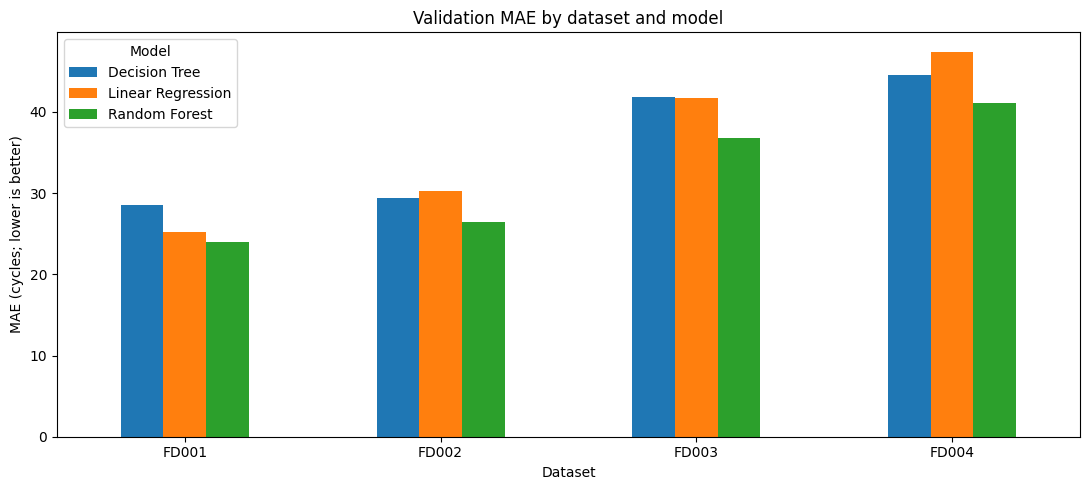

In [13]:
pivot_mae = validation_results_df.pivot(index="Dataset", columns="Model", values="MAE")
ax = pivot_mae.plot(kind="bar", figsize=(11, 5))
ax.set_title("Validation MAE by dataset and model")
ax.set_ylabel("MAE (cycles; lower is better)")
ax.set_xlabel("Dataset")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Final test-set prediction

For each dataset, the test file contains partial histories. We select the latest available row for each test engine and predict its RUL.

The official `RUL_FD00X.txt` file provides the reference RUL for each test engine. These reference values are used only for evaluation after predictions have been generated; they are never passed into the model as features.

To make the final test evaluation more reliable, we select the model with the lowest validation MAE for that FD subset and refit that model on all labelled training rows before predicting the test engines.

In [14]:
def select_latest_test_rows(test_df):
    latest_idx = test_df.groupby(ID_COL)[CYCLE_COL].idxmax()
    latest = test_df.loc[latest_idx].sort_values(ID_COL).reset_index(drop=True)
    return latest

test_results = []
all_test_predictions = []
final_models = {}

for name, data in datasets.items():
    # Select model using validation performance for this dataset.
    subset_results = validation_results_df[validation_results_df["Dataset"] == name]
    selected_model_name = subset_results.sort_values("MAE").iloc[0]["Model"]

    full_train = data["train_labeled"].copy()
    feature_cols = get_feature_columns(full_train)
    X_full = full_train[feature_cols]
    y_full = full_train[TARGET_COL]

    model = build_models()[selected_model_name]
    model.fit(X_full, y_full)
    final_models[name] = (model, feature_cols)

    latest_test = select_latest_test_rows(data["test"])
    X_test = latest_test[feature_cols]
    predicted_rul = model.predict(X_test)

    reference_rul = data["rul_reference"]
    if len(reference_rul) != len(latest_test):
        raise ValueError(
            f"{name}: reference RUL count ({len(reference_rul)}) does not match "
            f"test engine count ({len(latest_test)})."
        )

    metrics = regression_metrics(reference_rul, predicted_rul)
    test_results.append({
        "Dataset": name,
        "Selected model": selected_model_name,
        **metrics,
        "Test engines": len(latest_test)
    })

    pred_df = pd.DataFrame({
        "Dataset": name,
        "Engine_ID": latest_test[ID_COL].to_numpy(),
        "Last_observed_cycle": latest_test[CYCLE_COL].to_numpy(),
        "Actual_RUL": reference_rul,
        "Predicted_RUL": predicted_rul,
        "Absolute_Error": np.abs(reference_rul - predicted_rul)
    })
    all_test_predictions.append(pred_df)

test_results_df = pd.DataFrame(test_results)
test_predictions_df = pd.concat(all_test_predictions, ignore_index=True)

display(test_results_df)
display(test_predictions_df.head(10))

,Dataset,Selected model,MAE,RMSE,R2,Test engines
0,FD001,Random Forest,20.164360,26.453775,0.594757,100
1,FD002,Random Forest,20.546258,28.686918,0.715458,259
2,FD003,Random Forest,26.053228,35.604494,0.260223,100
3,FD004,Random Forest,28.864977,41.174942,0.429712,248


,Dataset,Engine_ID,Last_observed_cycle,Actual_RUL,Predicted_RUL,Absolute_Error
0,FD001,1,31,112.0,172.933062,60.933062
1,FD001,2,49,98.0,150.853737,52.853737
2,FD001,3,126,69.0,54.626746,14.373254
3,FD001,4,106,82.0,73.680061,8.319939
4,FD001,5,98,91.0,98.524655,7.524655
5,FD001,6,105,93.0,90.710135,2.289865
6,FD001,7,160,91.0,116.574477,25.574477
7,FD001,8,166,95.0,66.350595,28.649405
8,FD001,9,55,111.0,142.387902,31.387902
9,FD001,10,192,96.0,117.399368,21.399368


## 12. Interpret a prediction

For every test engine, the model directly predicts RUL. It does **not** receive the unknown failure cycle.

Example interpretation (illustrative only):
- Last observed cycle: 100
- Predicted RUL: 42 cycles
- Estimated failure cycle: 100 + 42 = 142

The estimated failure cycle is derived from the prediction; it is not the model's direct output. Actual test RUL values are available in the benchmark file only for evaluation.

In [15]:
# Show a small number of predictions with the largest absolute errors.
display(
    test_predictions_df.sort_values("Absolute_Error", ascending=False).head(10)
)

,Dataset,Engine_ID,Last_observed_cycle,Actual_RUL,Predicted_RUL,Absolute_Error
562,FD004,104,65,120.0,259.127509,139.127509
510,FD004,52,58,151.0,281.064637,130.064637
567,FD004,109,66,126.0,254.557887,128.557887
604,FD004,146,84,100.0,225.992491,125.992491
464,FD004,6,146,78.0,198.112512,120.112512
687,FD004,229,20,120.0,237.457382,117.457382
600,FD004,142,69,108.0,220.016091,112.016091
468,FD004,10,23,162.0,270.153194,108.153194
703,FD004,245,63,131.0,238.519666,107.519666
469,FD004,11,82,143.0,249.794297,106.794297


## 13. Feature importance (Random Forest)

Feature importance provides a simple interpretation of which input variables were most useful to the Random Forest model. Importance is a model-based association measure; it does not prove that a feature causes engine degradation.

We fit a Random Forest on each complete training subset and display the ten highest-ranked features.

In [ ]:
feature_importance_rows = []

# Ensure final_models exists, or fallback to fitting Random Forest for each dataset
if "final_models" not in globals():
    final_models = {}

for name, data in datasets.items():
    train_labeled = data["train_labeled"]
    feature_cols = get_feature_columns(train_labeled)

    # Check if a fitted model is available in final_models
    rf_pipe = None
    if name in final_models:
        candidate_model, candidate_cols = final_models[name]
        rf_step = candidate_model.named_steps.get("model", None) if hasattr(candidate_model, "named_steps") else None
        if rf_step is not None and hasattr(rf_step, "feature_importances_"):
            rf_pipe = candidate_model
            feature_cols = candidate_cols

    # If model is not Random Forest or not yet fitted, fit a Random Forest for interpretation
    if rf_pipe is None:
        rf_pipe = build_models()["Random Forest"]
        rf_pipe.fit(train_labeled[feature_cols], train_labeled[TARGET_COL])

    rf = rf_pipe.named_steps["model"]
    importances = rf.feature_importances_
    top_idx = np.argsort(importances)[::-1][:10]

    for rank, idx in enumerate(top_idx, start=1):
        feature_importance_rows.append({
            "Dataset": name,
            "Rank": rank,
            "Feature": feature_cols[idx],
            "Importance": importances[idx]
        })

feature_importance_df = pd.DataFrame(feature_importance_rows)
display(feature_importance_df[feature_importance_df["Dataset"] == "FD004"])

In [ ]:
for name in datasets:
    subset = feature_importance_df[feature_importance_df["Dataset"] == name].sort_values("Importance")
    plt.figure(figsize=(8, 5))
    plt.barh(subset["Feature"], subset["Importance"])
    plt.title(f"{name}: top Random Forest features")
    plt.xlabel("Feature importance")
    plt.tight_layout()
    plt.show()

## 14. Save outputs

The notebook saves:
- Validation metrics for all models and all four datasets.
- Test metrics for the selected model on each dataset.
- Test-engine predictions, reference RUL and absolute errors.
- Feature importance rankings.

These files provide evidence for the Results and Discussion chapter of the report.

In [ ]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

validation_results_df.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
test_results_df.to_csv(OUTPUT_DIR / "test_model_metrics.csv", index=False)
test_predictions_df.to_csv(OUTPUT_DIR / "test_rul_predictions_all_datasets.csv", index=False)
feature_importance_df.to_csv(OUTPUT_DIR / "random_forest_feature_importance.csv", index=False)

print("Saved output files to:", OUTPUT_DIR.resolve())
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", file.name)

## 15. Conclusion

This project follows the Predictive Analytics / KDD process from problem identification and data understanding through preprocessing, model development, evaluation and interpretation. It uses four C-MAPSS datasets and three traditional regression algorithms. The model estimates RUL from the latest available sensor observation of each test engine. Model quality is assessed against the benchmark reference RUL values using MAE, RMSE and R².

The selected model and numerical results should be reported from the outputs generated when this notebook is executed.